In [1]:
from astropy.io import fits
from astropy.io import ascii
from astropy.table import Table

import glob
import numpy as np
import matplotlib

from matplotlib import pyplot as plt

from tqdm import tnrange,tqdm_notebook
from pkg.resample_spec_fluxconv import resample_spec_fluxconv

import warnings
warnings.filterwarnings("ignore")

In [11]:
10**4.2

15848.93192461114

# SPSTD check

## Feige 66

(-14.0, -11.5)

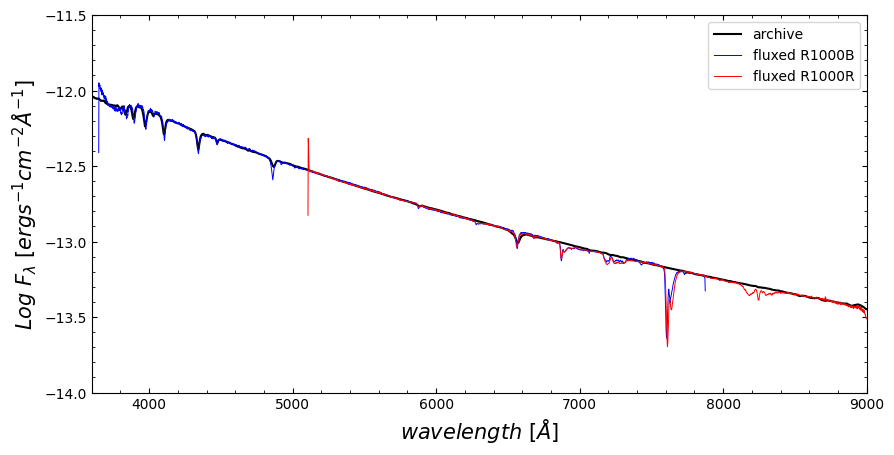

In [268]:
feige66_arch   = fits.open("data/GTC-OSIRIS/SPSTD_pypeit/feige66_002.fits.gz")
feige66_r      = fits.open("data/GTC-OSIRIS/SPSTD_obs/spec1d_0002617573-20200716-OSIRIS-OsirisLongSlitSpectroscopy-SPSTD_Feige66_OSIRIS_20200716T210937.199.fits")
feige66_b      = fits.open("data/GTC-OSIRIS/SPSTD_obs/spec1d_0002617572-20200716-OSIRIS-OsirisLongSlitSpectroscopy-SPSTD_Feige66_OSIRIS_20200716T210847.199.fits")
feige66_sens_b = fits.open("data/GTC-OSIRIS/SPSTD_obs/SPSTD_Feige66_R1000B_sensfunc.fits")
feige66_sens_r = fits.open("data/GTC-OSIRIS/SPSTD_obs/SPSTD_Feige66_R1000R_sensfunc.fits")

fig = plt.figure(figsize=(10,5),dpi = 100)
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True

ax = fig.add_subplot(111)
ax.set_xlabel(r'${wavelength\ [\AA]}$',fontsize=15)
ax.set_ylabel(r'${Log\ F_{\lambda}\ [ergs^{-1}cm^{-2}\AA^{-1}]}$',fontsize=15)
ax.plot(feige66_arch[1].data["WAVELENGTH"],np.log10(feige66_arch[1].data["FLUX"]),'k',label="archive")
ax.plot(feige66_b[1].data["OPT_WAVE"],np.log10(feige66_b[1].data["OPT_FLAM"]*10**(-17)),'b',lw = 0.7,label = 'fluxed R1000B')
ax.plot(feige66_r[2].data["OPT_WAVE"],np.log10(feige66_r[2].data["OPT_FLAM"]*10**(-17)),'r',lw = 0.7,label = 'fluxed R1000R')
plt.legend()
plt.xlim(3600,9000)
plt.ylim(-14,-11.5)

## GD 153

(-15.0, -12.5)

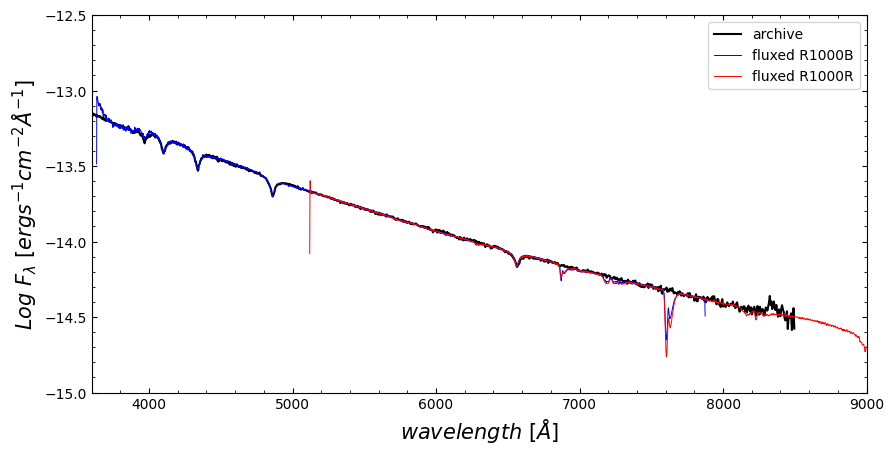

In [270]:
gd153_arch   = fits.open("data/GTC-OSIRIS/SPSTD_pypeit/gd153_fos_003.fits.gz")
gd153_b      = fits.open("data/GTC-OSIRIS/SPSTD_obs/spec1d_0002580957-20200525-OSIRIS-OsirisLongSlitSpectroscopy-SPSTD_GD153_OSIRIS_20200525T212251.492.fits")
gd153_r      = fits.open("data/GTC-OSIRIS/SPSTD_obs/spec1d_0002580958-20200525-OSIRIS-OsirisLongSlitSpectroscopy-SPSTD_GD153_OSIRIS_20200525T212448.492.fits")
gd153_sens_b = fits.open("data/GTC-OSIRIS/SPSTD_obs/SPSTD_GD153_R1000B_sensfunc.fits")
gd153_sens_r = fits.open("data/GTC-OSIRIS/SPSTD_obs/SPSTD_GD153_R1000R_sensfunc.fits")

fig = plt.figure(figsize=(10,5),dpi = 100)
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True

ax = fig.add_subplot(111)
ax.set_xlabel(r'${wavelength\ [\AA]}$',fontsize=15)
ax.set_ylabel(r'${Log\ F_{\lambda}\ [ergs^{-1}cm^{-2}\AA^{-1}]}$',fontsize=15)
ax.plot(gd153_arch[1].data["WAVELENGTH"],np.log10(gd153_arch[1].data["FLUX"]),'k',label="archive")
ax.plot(gd153_b[1].data["OPT_WAVE"],np.log10(gd153_b[1].data["OPT_FLAM"]*10**(-17)),'b',lw = 0.7,label = 'fluxed R1000B')
ax.plot(gd153_r[1].data["OPT_WAVE"],np.log10(gd153_r[1].data["OPT_FLAM"]*10**(-17)),'r',lw = 0.7,label = 'fluxed R1000R')
plt.legend()
plt.xlim(3600,9000)
plt.ylim(-15,-12.5)

# Combine grism


In [7]:
def re_norm(wv_fd, fl_fd, wv_nonfd, fl_nonfd, var_nonfd): #fd=fiducial
    wv_fd_min = np.min(wv_fd)
    wv_fd_max = np.max(wv_fd)
    
    wv_nonfd_min = np.min(wv_nonfd)
    wv_nonfd_max = np.max(wv_nonfd)
    
    if wv_fd_min > wv_nonfd_min:
        id_fd    = np.where( wv_fd < wv_nonfd_max)
        id_nonfd = np.where( wv_nonfd > wv_fd_min)
        norm     = np.median(fl_fd[id_fd])/np.median(fl_nonfd[id_nonfd])
        
    if wv_fd_min < wv_nonfd_min:
        id_fd    = np.where( wv_fd > wv_nonfd_min)
        id_nonfd = np.where( wv_nonfd < wv_fd_max)
        norm     = np.median(fl_fd[id_fd])/np.median(fl_nonfd[id_nonfd])

    fl_nonfd = fl_nonfd*norm
    var_nonfd= var_nonfd*norm**2
    return fl_nonfd, var_nonfd

In [8]:
def resample_spec(new_wave, old_wave, old_flux, old_var):
    old_strline     = np.zeros(len(old_wave))
    id              = np.where(old_var < 0)
    old_var[id]     = -old_var[id] 
    old_strline[id] = 1.0
        
    old_err               = old_var**0.5
    new_fl, new_err       = resample_spec_fluxconv(new_wave, old_wave, old_flux, old_err, extrap_treatment='zero')
    new_var               = new_err**2
    new_strline, ignore   = resample_spec_fluxconv(new_wave, old_wave, old_strline, old_strline, extrap_treatment='zero')
    
    return new_fl, new_var, new_strline

In [221]:
def combine_grism(tar_name, cut_edge=False, save=True, plot=True):
    
    # load files
    gtc_path   = "data/GTC-OSIRIS/Sci_spec/"
    sdss_path  = "data/SDSS/"
    sdss_file  = glob.glob(sdss_path+"*"+tar_name+"*.fits")[0]
    gtc_B_file = glob.glob(gtc_path +"*"+tar_name+"*R1000B*.fits")[0]
    gtc_R_file = glob.glob(gtc_path +"*"+tar_name+"*R1000R*.fits")[0]
    
    # read file 
    # sdss 
    sdss_hdu = fits.open(sdss_file)
    # GTC 
    hdu_B = fits.open(gtc_B_file)
    hdu_R = fits.open(gtc_R_file)
    # data prep
    hdu_data_B  = hdu_B[1].data
    wave_B      = hdu_data_B["wave"]
    flux_B      = hdu_data_B["flux"]
    var_B       = 1/np.sqrt(hdu_data_B["ivar"])
    var_B[np.isinf(var_B)] = 0
    hdu_data_R  = hdu_R[1].data
    wave_R      = hdu_R[1].data["wave"]
    flux_R      = hdu_R[1].data["flux"]
    var_R       = 1/np.sqrt(hdu_R[1].data["ivar"])
    var_R[np.isinf(var_R)] = 0
    
    if cut_edge:
        wave_B = wave_B[:-5]
        flux_B = flux_B[:-5]
        var_B  = var_B[:-5]
        wave_R = wave_R[5:]
        flux_R = flux_R[5:]
        var_R  = var_R[5:]
    
    # set new wave grid
    wg_min, wg_max = 3630., 10000. 
    dlogwg         = 1/1000./np.log(10)/2
    n_wave         = (np.log10(wg_max)-np.log10(wg_min))/dlogwg
    log_new_wave   = np.log10(wg_min) + np.arange(n_wave) * dlogwg
    wave_new       = 10**log_new_wave
    num_wave       = len(wave_new)
    
    # re-normalize R band flux & var
    flux_R_norm, var_R_norm   = re_norm(wave_B, flux_B, wave_R, flux_R, var_R)
    # re-sample B & R band spectrum
    new_flux_B, new_var_B, new_strlineB = resample_spec(wave_new, wave_B, flux_B, var_B)
    new_flux_R, new_var_R, new_strlineR = resample_spec(wave_new, wave_R, flux_R_norm, var_R_norm)
    
    # combine two grism 
    weightB = np.zeros(len(wave_new))
    idb     = np.where(new_var_B > 0)
    weightB[idb] = 1.0/new_var_B[idb]
    weightR = np.zeros(len(wave_new))
    idr     = np.where(new_var_R > 0)
    weightR[idr] = 1.0/new_var_R[idr]

    new_flux = ( new_flux_B*weightB + new_flux_R*weightR )/(weightB + weightR)
    new_var  = ( new_var_B*weightB**2 + new_var_R*weightR**2)/(weightB + weightR)**2     
    new_strline  = new_strlineB + new_strlineR
    ids          = np.where(new_strline > 0)
    new_var[ids] = -new_var[ids]
    
    if save:
        
        save_path = "data/GTC-OSIRIS/Sci_spec/combined_grism/"
        save_name = tar_name+"GTC_OSIRIS.fits"
        # creat new fits
        # read osiris & sdss fits.head
        hdu_hdr_B = hdu_B[0].header
        ###header
        hdr_list = ['RA','DEC','TARGET','DECKER','BINNING ','MJD','AIRMASS','EXPTIME','INSTRUME',
                    'DETECTOR','PYPELINE','PYP_SPEC','TELESCOP','LON-OBS','LAT-OBS','ALT-OBS']
        hdr = fits.Header()
        hdr['CRVAL3']    = ( np.log10(wave_new[0]), ', logwv_start')
        hdr['num_wave']  = len(wave_new) 
        hdr['CDELT3']    = ( np.log10(wave_new[1])-np.log10(wave_new[0]), ', det_logwv' )
        hdr['z']         = ( sdss_hdu[2].data['z'][0], "redshift")
        hdr['FluxBUNIT'] = '10**(-17)erg.s**(-1).cm**(-2).angstrom**(-1)'
        
        for key in hdr_list:
            hdr[key] = (hdu_hdr_B[key],hdu_hdr_B.comments[key])
        empty_primary = fits.PrimaryHDU(header=hdr)

        ###table
        c1 = fits.Column(name='wave', array = wave_new, format='D')
        c2 = fits.Column(name='flux', array = new_flux, format='D')
        c3 = fits.Column(name='var' , array = new_var , format='D')
        table_hdu = fits.BinTableHDU.from_columns([c1,c2,c3])

        hdul = fits.HDUList([empty_primary,table_hdu])
        hdul.writeto(save_path+save_name, overwrite=True)
        print("Save to .fits file successfully!")
        
    if plot:
        
        fig = plt.figure(figsize=(10,5),dpi=100)
        plt.rcParams["xtick.direction"] = "in"
        plt.rcParams["ytick.direction"] = "in"
        plt.rcParams["xtick.top"] = True
        plt.rcParams["ytick.right"] = True
        plt.rcParams["xtick.minor.visible"] = True
        plt.rcParams["ytick.minor.visible"] = True
        
        ax  = plt.subplot(111)
        ax.set_xlabel(r'${Wavelength\ [\AA]}$',fontsize=15)
        ax.set_ylabel(r'${Flux\ [10^{-17}ergs^{-1}cm^{-2}\AA^{-1}]}$',fontsize=15)
        ax.set_title(tar_name + " combine spectrum", fontsize=15)
        z = sdss_hdu[2].data['z'][0]
        ax.plot(wave_new/(1+z),new_flux,'k',label = "combined spectrum")
        
        plt.legend()
        plt.xlim(3600/(1+z),9500/(1+z))
        wmsk = (wave_new>3600)&(wave_new<9500)
        plt.ylim(np.nanmin(new_flux[wmsk]),np.nanmax(new_flux[wmsk]))
        
    return np.array([wave_new, new_flux, new_var])

In [ ]:
sdss_list = [name for name in glob.glob("data/SDSS/*.fits")]
tar_list  = np.array([name[10:20] for name in sdss_list])
for i in tnrange(len(tar_list)):
    new_spec = combine_grism(tar_list[i],cut_edge=True, save=False, plot=False)

## combine outliner

Save to .fits file successfully!


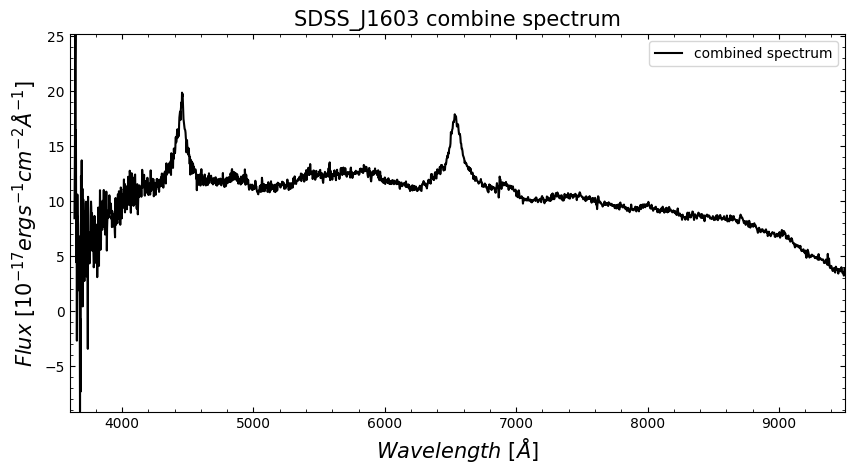

In [291]:
# load files
tar_name = "SDSS_J1603"
cut_edge = 1
plot     = 1
show_RB  = 0
save     = 1

gtc_path   = "data/GTC-OSIRIS/Sci_spec/"
sdss_path  = "data/SDSS/"
sdss_file  = glob.glob(sdss_path+"*"+tar_name+"*.fits")[0]
gtc_B_file = glob.glob(gtc_path +"*"+tar_name+"*R1000B*.fits")[0]
gtc_R_file = glob.glob(gtc_path +"*"+tar_name+"*R1000R*.fits")[0]

# read file 
# sdss 
sdss_hdu = fits.open(sdss_file)
# GTC 
hdu_B = fits.open(gtc_B_file)
hdu_R = fits.open(gtc_R_file)
# data prep
hdu_data_B  = hdu_B[1].data
wave_B      = hdu_data_B["wave"]
flux_B      = hdu_data_B["flux"]
var_B       = 1/np.sqrt(hdu_data_B["ivar"])
var_B[np.isinf(var_B)] = 0
hdu_data_R  = hdu_R[1].data
wave_R      = hdu_R[1].data["wave"]
flux_R      = hdu_R[1].data["flux"]
var_R       = 1/np.sqrt(hdu_R[1].data["ivar"])
var_R[np.isinf(var_R)] = 0

if cut_edge:
    wave_B = wave_B[:-5]
    flux_B = flux_B[:-5]
    var_B  = var_B[:-5]
    wave_R = wave_R[5:]
    flux_R = flux_R[5:]
    var_R  = var_R[5:]

# set new wave grid
wg_min, wg_max = 3630., 10000. 
dlogwg         = 1/1000./np.log(10)/2
n_wave         = (np.log10(wg_max)-np.log10(wg_min))/dlogwg
log_new_wave   = np.log10(wg_min) + np.arange(n_wave) * dlogwg
wave_new       = 10**log_new_wave
num_wave       = len(wave_new)

# re-normalize R band flux & var
flux_R_norm, var_R_norm   = re_norm(wave_B, flux_B, wave_R, flux_R, var_R)
# re-sample B & R band spectrum
new_flux_B, new_var_B, new_strlineB = resample_spec(wave_new, wave_B, flux_B, var_B)
new_flux_R, new_var_R, new_strlineR = resample_spec(wave_new, wave_R, flux_R_norm, var_R_norm)

# combine two grism 
weightB = np.zeros(len(wave_new))
idb     = np.where(wave_new < 6000)
weightB[idb] = 1.0/new_var_B[idb]
weightR = np.zeros(len(wave_new))
idr     = np.where(wave_new > 6000)
weightR[idr] = 1.0/new_var_R[idr]

new_flux = ( new_flux_B*weightB + new_flux_R*weightR )/(weightB + weightR)
new_var  = ( new_var_B*weightB**2 + new_var_R*weightR**2)/(weightB + weightR)**2     
new_strline  = new_strlineB + new_strlineR
ids          = np.where(new_strline > 0)
new_var[ids] = -new_var[ids]

if plot:
        
    fig = plt.figure(figsize=(10,5),dpi=100)
    plt.rcParams["xtick.direction"] = "in"
    plt.rcParams["ytick.direction"] = "in"
    plt.rcParams["xtick.top"] = True
    plt.rcParams["ytick.right"] = True
    plt.rcParams["xtick.minor.visible"] = True
    plt.rcParams["ytick.minor.visible"] = True

    ax  = plt.subplot(111)
    ax.set_xlabel(r'${Wavelength\ [\AA]}$',fontsize=15)
    ax.set_ylabel(r'${Flux\ [10^{-17}ergs^{-1}cm^{-2}\AA^{-1}]}$',fontsize=15)
    ax.set_title(tar_name + " combine spectrum", fontsize=15)
    z = sdss_hdu[2].data['z'][0]
    ax.plot(wave_new,new_flux,'k',label = "combined spectrum")
    
    if show_RB:
        ax.plot(wave_B,flux_B,'C0',lw=0.7,label="R1000B")
        ax.plot(wave_R,flux_R,'r' ,lw=0.7,label="R1000R")

    plt.legend()
    plt.xlim(3600,9500)
    wmsk = (wave_new>3600)&(wave_new<9500)
    plt.ylim(np.nanmin(new_flux[wmsk]),np.nanmax(new_flux[wmsk]))
    
if save:
        
    save_path = "data/GTC-OSIRIS/Sci_spec/combined_grism/"
    save_name = tar_name+"GTC_OSIRIS.fits"
    # creat new fits
    # read osiris & sdss fits.head
    hdu_hdr_B = hdu_B[0].header
    ###header
    hdr_list = ['RA','DEC','TARGET','DECKER','BINNING ','MJD','AIRMASS','EXPTIME','INSTRUME',
                'DETECTOR','PYPELINE','PYP_SPEC','TELESCOP','LON-OBS','LAT-OBS','ALT-OBS']
    hdr = fits.Header()
    hdr['CRVAL3']    = ( np.log10(wave_new[0]), ', logwv_start')
    hdr['num_wave']  = len(wave_new) 
    hdr['CDELT3']    = ( np.log10(wave_new[1])-np.log10(wave_new[0]), ', det_logwv' )
    hdr['z']         = ( sdss_hdu[2].data['z'][0], "redshift")
    hdr['FluxBUNIT'] = '10**(-17)erg.s**(-1).cm**(-2).angstrom**(-1)'

    for key in hdr_list:
        hdr[key] = (hdu_hdr_B[key],hdu_hdr_B.comments[key])
    empty_primary = fits.PrimaryHDU(header=hdr)

    ###table
    c1 = fits.Column(name='wave', array = wave_new, format='D')
    c2 = fits.Column(name='flux', array = new_flux, format='D')
    c3 = fits.Column(name='var' , array = new_var , format='D')
    table_hdu = fits.BinTableHDU.from_columns([c1,c2,c3])

    hdul = fits.HDUList([empty_primary,table_hdu])
    hdul.writeto(save_path+save_name, overwrite=True)
    print("Save to .fits file successfully!")

# Spectrum check


In [2]:
def tar_chk_sdss(tar_name):
    sdss_path  = "data/SDSS/"
    sdss_file  = glob.glob(sdss_path+"*"+tar_name+"*.fits")[0]
    spec_data = fits.open(sdss_file)
    z_ = spec_data[2].data["Z"]
    wave = 10**spec_data[1].data["loglam"]/(1+z_)
    flux = spec_data[1].data["flux"]
    sky  = spec_data[1].data["sky"]
    model  = spec_data[1].data["model"]
    
    fig = plt.figure(figsize=(10,5),dpi = 100)
    plt.rcParams["xtick.direction"] = "in"
    plt.rcParams["ytick.direction"] = "in"
    plt.rcParams["xtick.top"] = True
    plt.rcParams["ytick.right"] = True
    plt.rcParams["xtick.minor.visible"] = True
    plt.rcParams["ytick.minor.visible"] = True

    ax = fig.add_subplot(111)
    ax.set_title(tar_name + " SDSS", fontsize=15)
#     ax.set_xlabel(r'${wavelength\ [\AA]}$',fontsize=15)
    ax.set_ylabel(r'${\rm Flux\ [10^{-17}ergs^{-1}cm^{-2}\AA^{-1}]}$',fontsize=15)
    ax.plot(wave,flux, 'k',lw=0.5,label='obs.')
    ax.plot(wave,model,'r',lw=0.5,label='bestfit')
    plt.legend()
    
    return spec_data,z_

In [3]:
def tar_chk_gtc(tar_name,show_RB=False, show_combine=True):
    
    gtc_path   = "data/GTC-OSIRIS/Sci_spec/"
    combined_path = "data/GTC-OSIRIS/Sci_spec/combined_grism/"
    gtc_B_file = glob.glob(gtc_path +"*"+tar_name+"*R1000B*.fits")[0]
    gtc_R_file = glob.glob(gtc_path +"*"+tar_name+"*R1000R*.fits")[0]
    gtc_C_file = glob.glob(combined_path+tar_name+"*.fits")[0]
    gtc_B_data = fits.open(gtc_B_file)
    gtc_R_data = fits.open(gtc_R_file)
    gtc_C_data = fits.open(gtc_C_file)
    
    wave_r = gtc_R_data[1].data["wave"]
    flux_r = gtc_R_data[1].data["flux"]
    wave_b = gtc_B_data[1].data["wave"]
    flux_b = gtc_B_data[1].data["flux"]
    wave_c = gtc_C_data[1].data["wave"]
    flux_c = gtc_C_data[1].data["flux"]
    z      = gtc_C_data[0].header["z"]
    
    # plot 
    fig = plt.figure(figsize=(10,5),dpi = 100)
    plt.rcParams["xtick.direction"] = "in"
    plt.rcParams["ytick.direction"] = "in"
    plt.rcParams["xtick.top"] = True
    plt.rcParams["ytick.right"] = True
    plt.rcParams["xtick.minor.visible"] = True
    plt.rcParams["ytick.minor.visible"] = True

    ax = fig.add_subplot(111)
    ax.set_title(tar_name + " GTC-OSIRIS", fontsize=15)
    ax.set_xlabel(r'${\rm Rest Wavelength\ [\AA]}$',fontsize=15)
    ax.set_ylabel(r'${\rm Flux\ [10^{-17}ergs^{-1}cm^{-2}\AA^{-1}]}$',fontsize=15)
    
    if show_RB:
        ax.plot(wave_b/(1+z),flux_b,'C0',lw=0.7,label="R1000B")
        ax.plot(wave_r/(1+z),flux_r,'r' ,lw=0.7,label="R1000R")
    if show_combine:
        ax.plot(wave_c/(1+z),flux_c,'k' ,lw=0.7,label="combine")
        
    plt.legend()
    plt.xlim(3600/(1+z),9500/(1+z))
    wmsk = (wave_c>3600)&(wave_c<9500)
    plt.ylim(np.nanmin(flux_c[wmsk]),np.nanmax(flux_c[wmsk]))
    
    return gtc_C_data

## SDSSJ1427

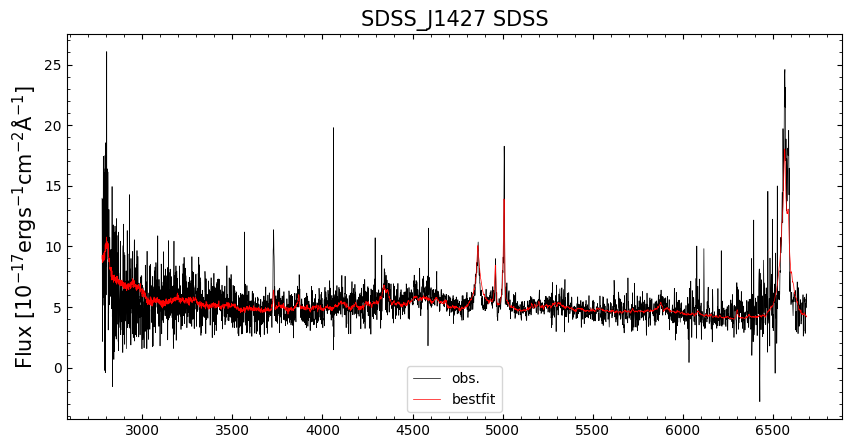

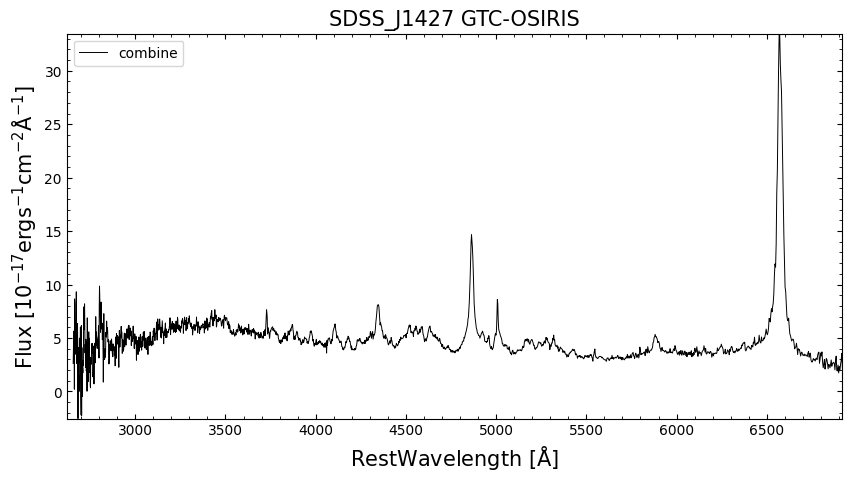

In [4]:
tar_name = "SDSS_J1427"
sdss_spec_1427,z_1427 = tar_chk_sdss(tar_name)
gtc_spec_1427         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)

In [5]:
gtc_spec_1427[0].header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
CRVAL3  =    3.559906625036112 / , logwv_start                                  
NUM_WAVE=                 2027                                                  
CDELT3  = 0.000217147240951565 / , det_logwv                                    
Z       =   0.3736243844032288 / redshift                                       
HIERARCH FluxBUNIT = '10**(-17)erg.s**(-1).cm**(-2).angstrom**(-1)'             
RA      =    217.0110291666666 / (J2000) RA in decimal degrees                  
DEC     =           29.5238125 / (J2000) DEC in decimal degrees                 
TARGET  = 'SDSS142746.39+293038.2' / Name of the target                         
DECKER  = 'LongSlits0.8Arcse

## SDSSJ1411

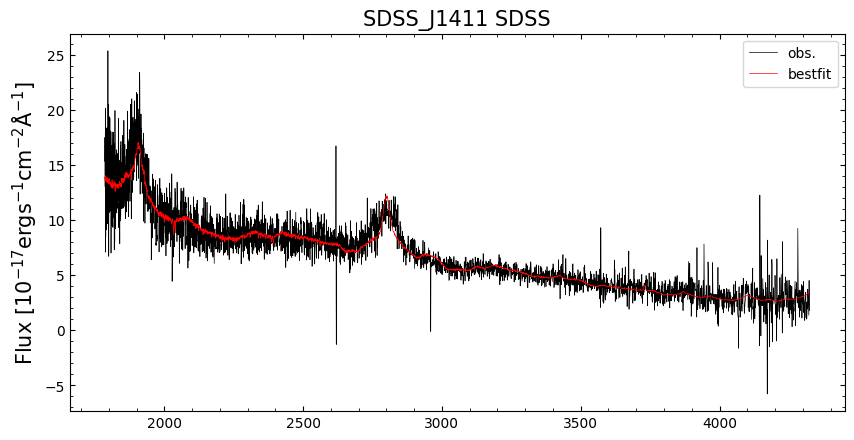

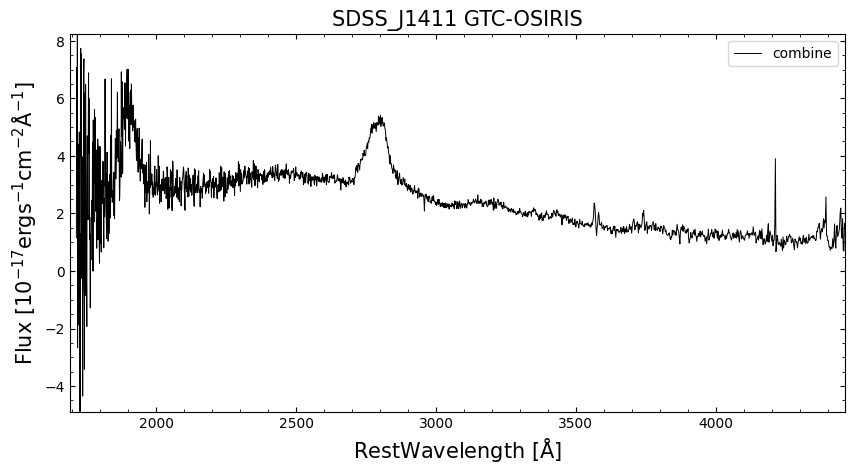

In [252]:
tar_name = "SDSS_J1411"
sdss_spec_1411,z_1411 = tar_chk_sdss(tar_name)
gtc_spec_1411         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)

## SDSSJ1418

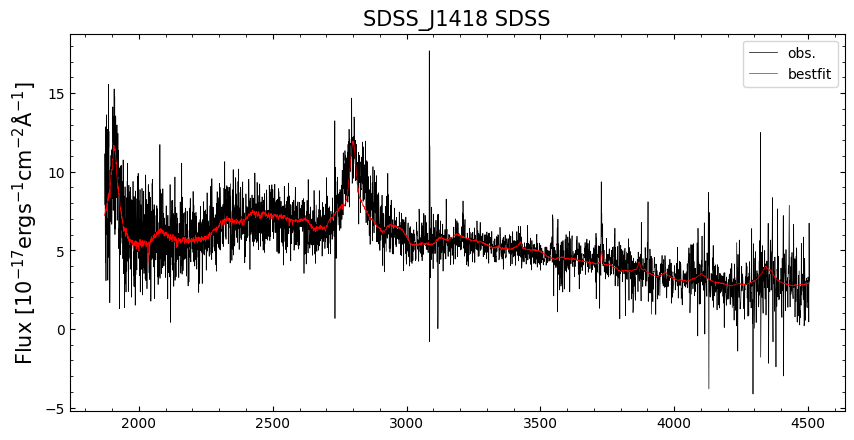

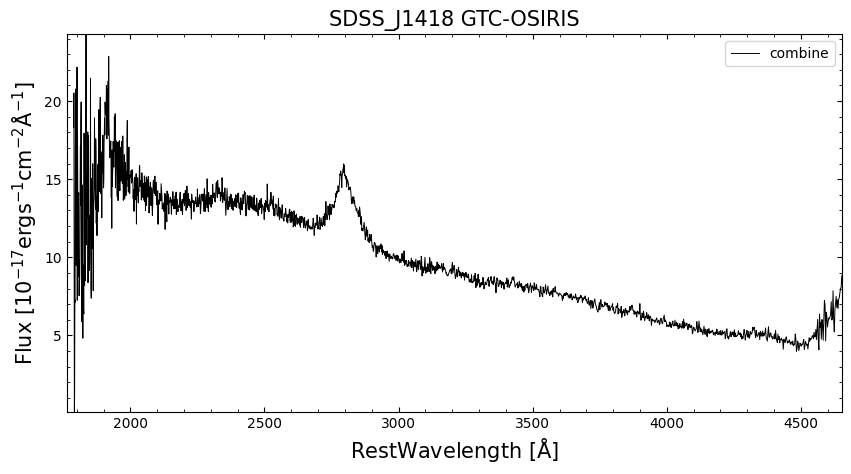

In [285]:
tar_name = "SDSS_J1418"
sdss_spec_1418,z_1418 = tar_chk_sdss(tar_name)
gtc_spec_1418         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)

## SDSSJ1420

In [2]:
tar_name = "SDSS_J1420"
sdss_spec_1420,z_1420 = tar_chk_sdss(tar_name)
gtc_spec_1420         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)
z_1420

NameError: name 'tar_chk_sdss' is not defined

In [1]:
sdss_spec_1420[1].header

NameError: name 'sdss_spec_1420' is not defined

In [13]:
wave = 10**sdss_spec_1420[1].data["loglam"]/(1+z_1420)
flux = sdss_spec_1420[1].data["flux"]

wave_c = gtc_spec_1420[1].data["wave"]
flux_c = gtc_spec_1420[1].data["flux"]

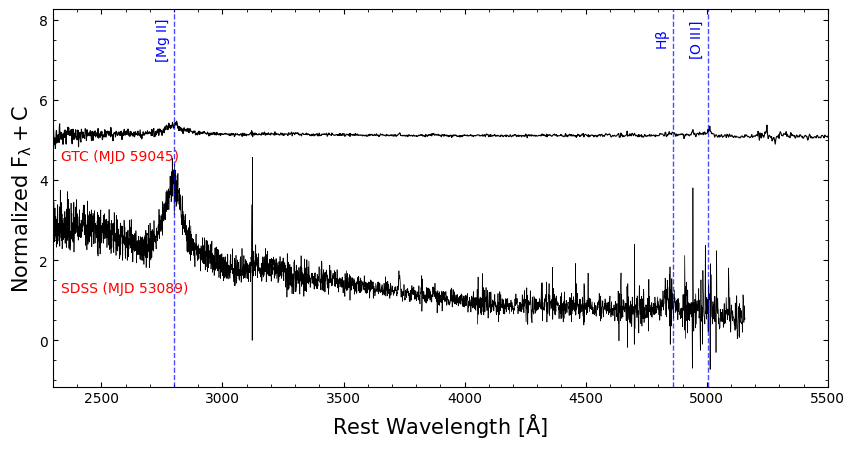

In [52]:
fig = plt.figure(figsize=(10,5),dpi = 100)
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True

ax = fig.add_subplot(111)
ax.set_xlabel(r"${\rm  Rest\ Wavelength\ [\AA]}$", fontsize=15)
ax.set_ylabel(r"${\rm  Normalized\ F_{\lambda}+C }$", fontsize=15)
ax.set_xlim(2300, 5500)
ax.plot(wave,flux/5, 'k',lw=0.5,label='SDSS')
ax.plot(wave_c/(1+z_1420),flux_c/5+5,'k' ,lw=0.8,label="GTC")

fontdict_emline=dict(fontsize=10, color='b',family='Times New Roman',weight='light')
color = 'b'
line_alpha = 0.7
line_lw = 1
ax.axvline(x = 2800, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.text(0.13 ,0.92,r'${\rm [Mg\ II]}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

ax.axvline(x = 4861, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.text(0.775,0.92,r'${\rm H\beta}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

# ax.axvline(x = 4959, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.axvline(x = 5007, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.text(0.82 ,0.92,r'${\rm [O\ III]}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

ax.text(0.01,0.6,'GTC (MJD 59045)',transform=ax.transAxes,fontdict={'size': '10', 'color': 'red'})
ax.text(0.01,0.25,'SDSS (MJD 53089)',transform=ax.transAxes,fontdict={'size': '10', 'color': 'red'})

ax.plot()
plt.savefig('image/SDSS_J1420_spec.pdf',dpi=600,bbox_inches='tight')

## SDSSJ1440

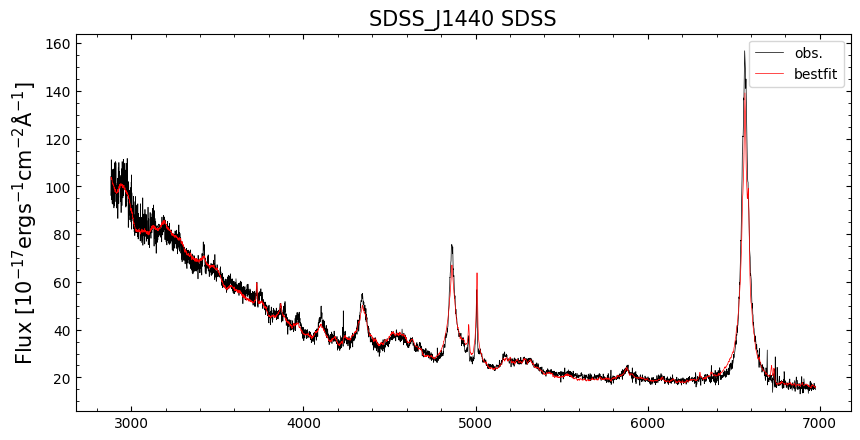

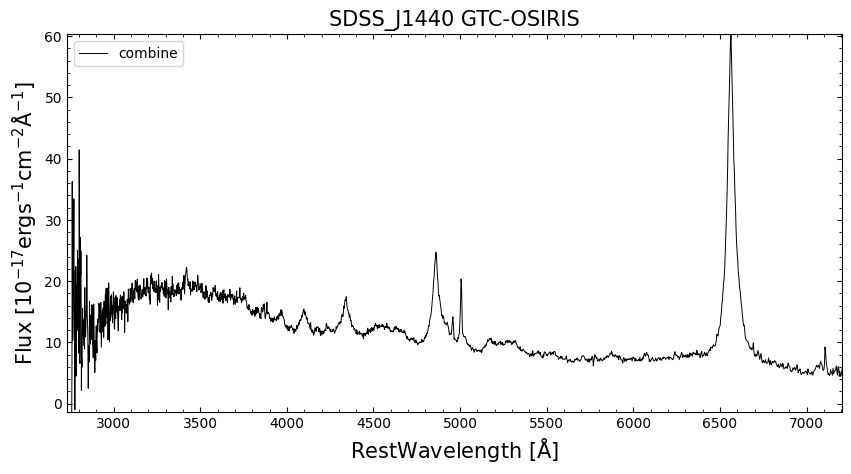

In [256]:
tar_name = "SDSS_J1440"
sdss_spec_1440,z_1440 = tar_chk_sdss(tar_name)
gtc_spec_1440         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)

## SDSSJ1603

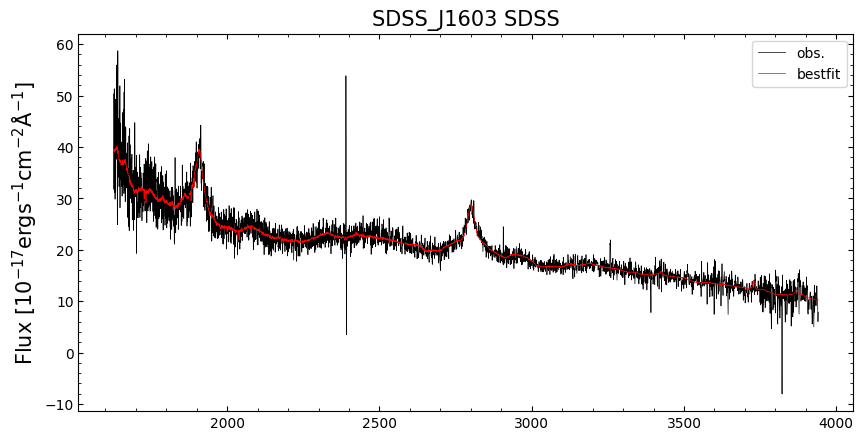

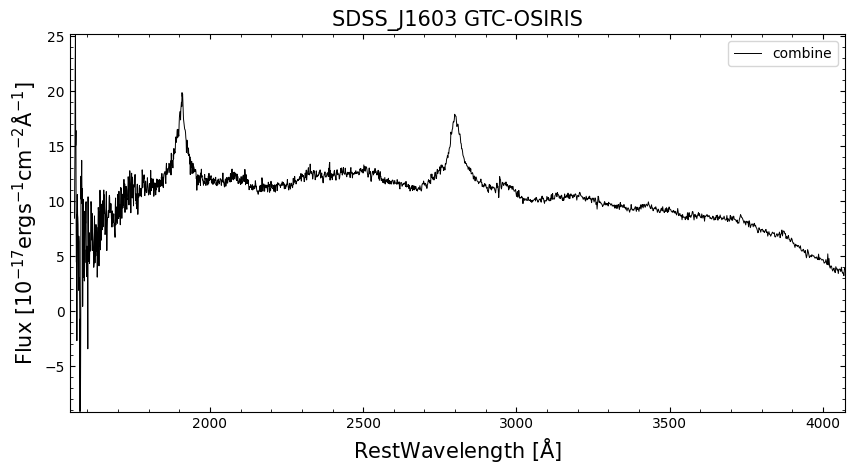

In [292]:
tar_name = "SDSS_J1603"
sdss_spec_1603,z_1603 = tar_chk_sdss(tar_name)
gtc_spec_1603         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)

## SDSSJ1607

array([0.4650761], dtype=float32)

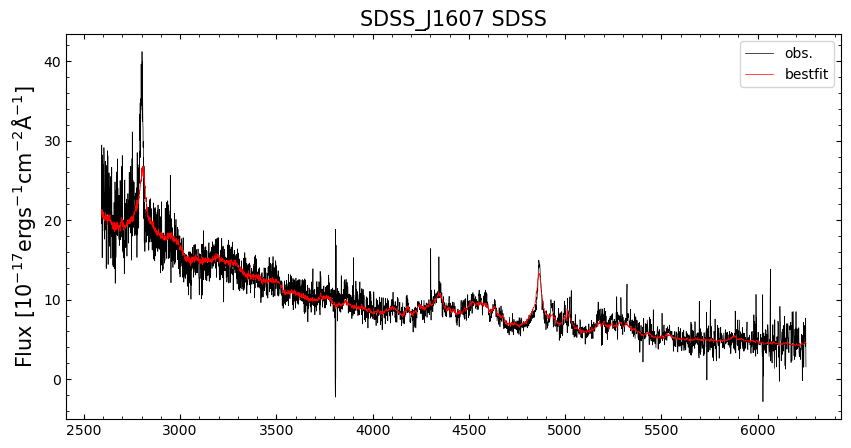

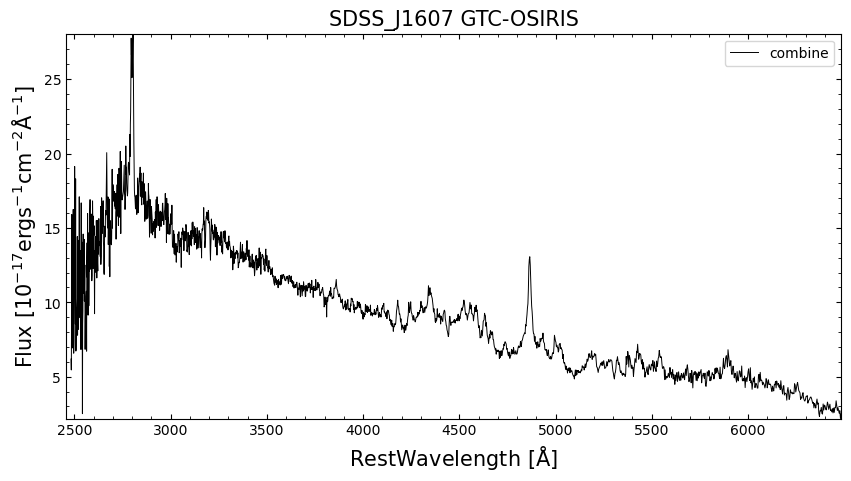

In [12]:
tar_name = "SDSS_J1607"
sdss_spec_1607,z_1607 = tar_chk_sdss(tar_name)
gtc_spec_1607         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)

z_1607

## SDSSJ1728

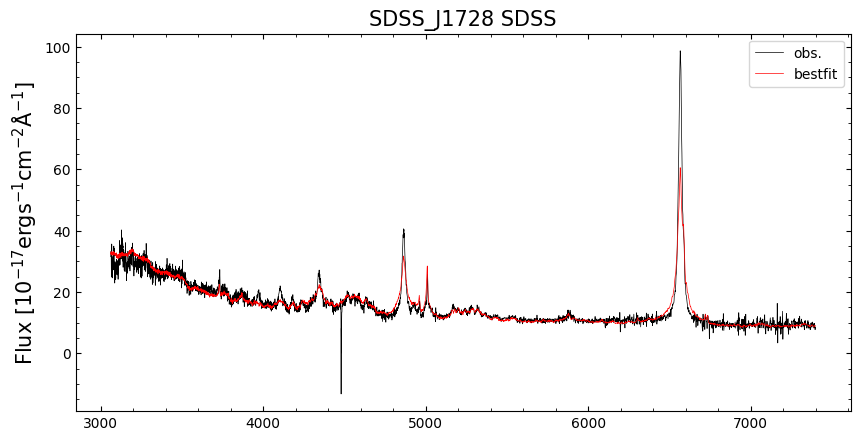

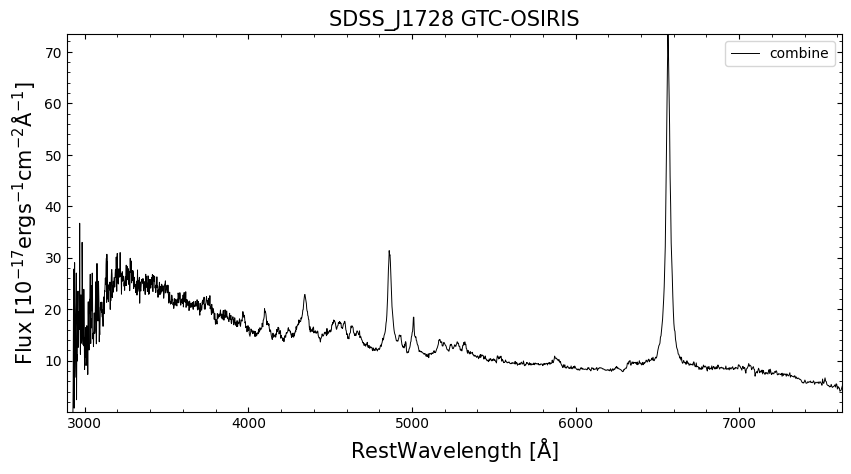

In [259]:
tar_name = "SDSS_J1728"
sdss_spec_1728,z_1728 = tar_chk_sdss(tar_name)
gtc_spec_1728         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)

## SDSSJ2127

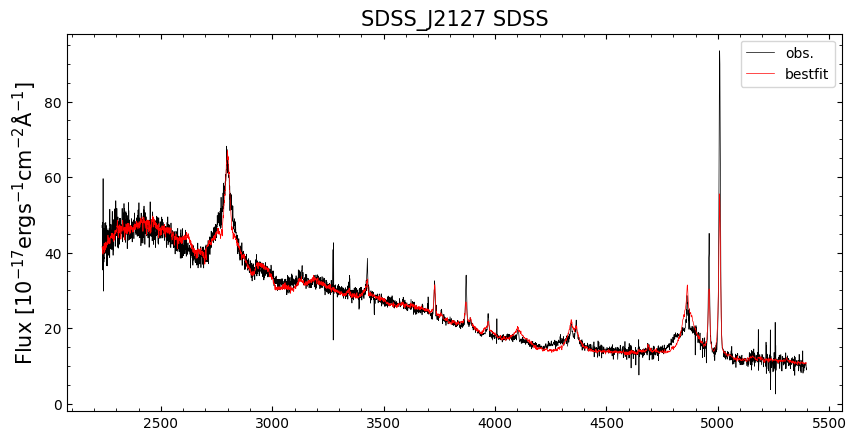

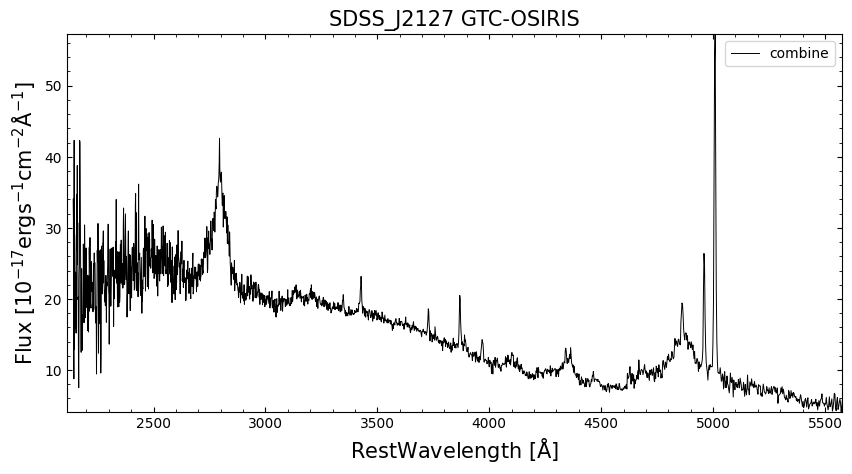

In [6]:
tar_name = "SDSS_J2127"
sdss_spec_2127,z_2127 = tar_chk_sdss(tar_name)
gtc_spec_2127         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)

## SDSSJ1617

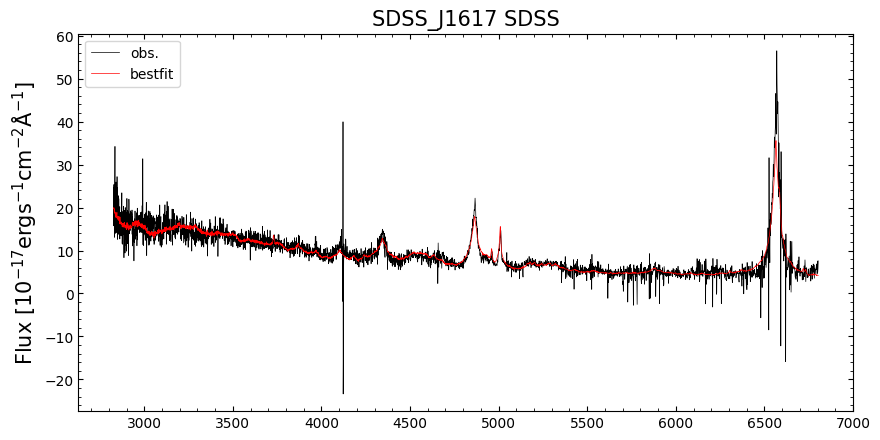

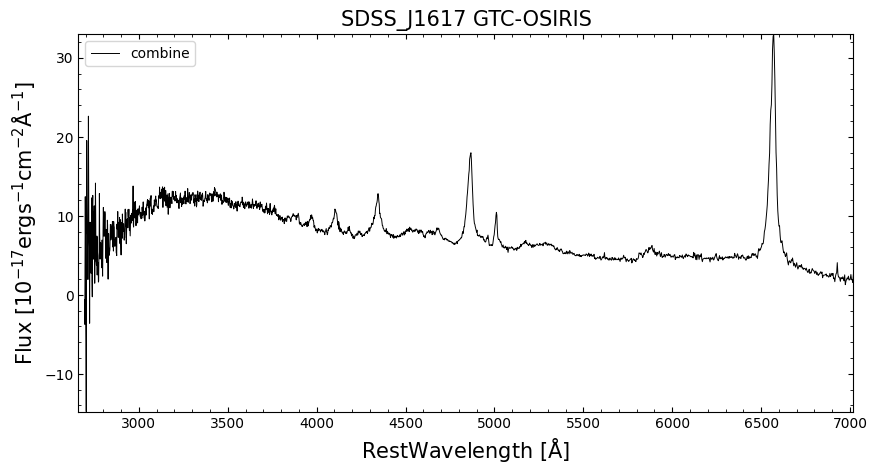

In [4]:
tar_name = "SDSS_J1617"
sdss_spec_1617,z_1617 = tar_chk_sdss(tar_name)
gtc_spec_1617         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)

## SDSSJ1452

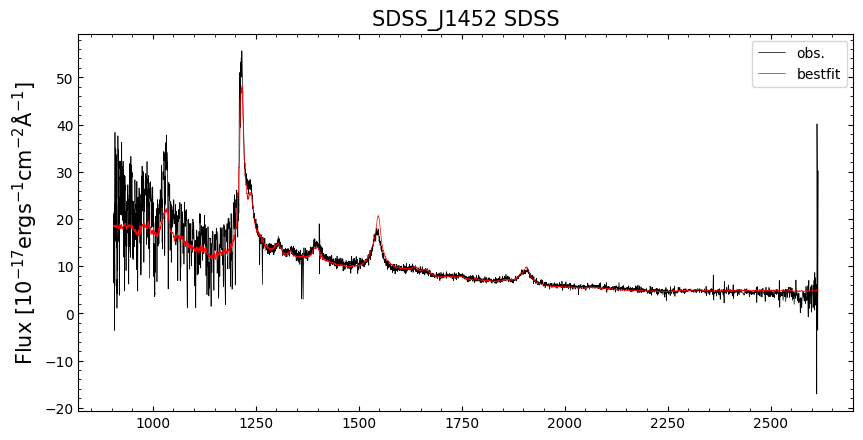

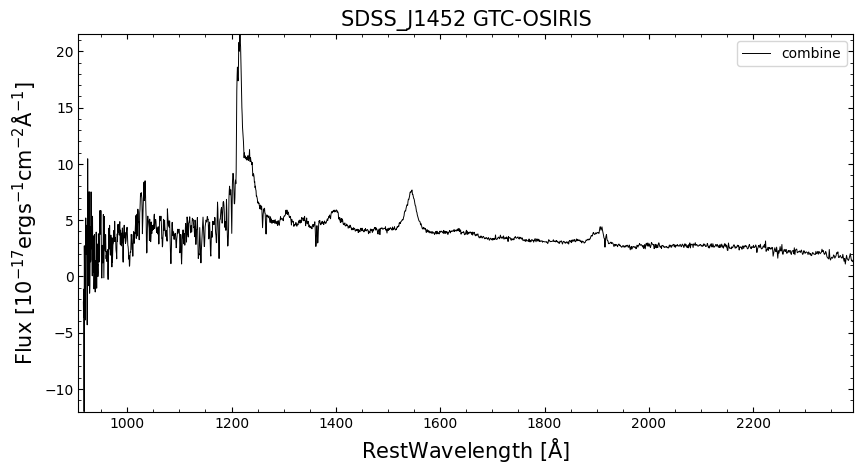

In [262]:
tar_name = "SDSS_J1452"
sdss_spec_1452,z_1452 = tar_chk_sdss(tar_name)
gtc_spec_1452         = tar_chk_gtc(tar_name,show_RB=False, show_combine=True)

# test 